# Prior exponencial de operações e skeletons RAW/TANH

Como uma prior que favorece árvores com mais operações cobre skeletons comparada a uma amostragem uniforme de ASTs?

A proteção seletiva `product_lags` é escolhida por amostra com probabilidade 0,5 antes da expansão. A AST escolhida define tanto a entrada quanto o alvo. Os fatores RAW e TANH têm identidades diferentes. A construção se inspira nas condições de Shao e Wu (2007, Theorem 5.1); a escolha do operador TANH e o algoritmo são do projeto.

In [1]:
from pathlib import Path
import sys
ROOT=next(p for p in (Path.cwd(),*Path.cwd().parents) if (p/'pyproject.toml').exists())
sys.path.insert(0,str(ROOT/'src'))
from dataclasses import replace
from collections import Counter
import numpy as np,pandas as pd,matplotlib.pyplot as plt
from tsfmxai.generators import RandomTreeConfig,sample_random_mechanism,derive_sample_seed,saturate_product_lags,CombinatorialTreeConfig,CombinatorialTreeSampler
from tsfmxai.representations import canonicalize_polynomial,format_monomial,Tanh,walk
from tsfmxai.symbolic_regression.canonical_data import select_canonical_mechanism
SEED=20261101
N=10000
base=RandomTreeConfig(minimum_operators=1,maximum_operators=6,num_series=1,
    minimum_lag=1,maximum_lag=6,parameter_probability=.4,lag_probability=.6)
weights=np.exp(.4*np.arange(6));weights/=weights.sum()
METHODS=('fixed_exponential','combinatorial')


Esta célula fixa seeds, vocabulário, tamanho das ASTs e condições comparadas.

In [2]:
def study(method):
    sampler=CombinatorialTreeSampler(CombinatorialTreeConfig(minimum_operators=1,
        maximum_operators=6,num_series=1,minimum_lag=1,maximum_lag=6,max_degree=4))
    counts=Counter();factors=Counter();degrees=Counter();reject=0;prefix=[];selected_count=0;activated_count=0
    for i in range(N):
        seed=derive_sample_seed(SEED,i)
        if method=='combinatorial':
            sample=sampler.sample(seed=seed,sample_index=i)
        else:
            p=float(np.random.default_rng(np.random.SeedSequence([SEED,i,2])).random()) if method=='per_tree_probabilities' else .4
            n=int(np.random.default_rng(np.random.SeedSequence([SEED,i,1])).choice(np.arange(1,7),p=weights))
            cfg=replace(base,minimum_operators=n,maximum_operators=n,
                        parameter_probability=p,lag_probability=1-p)
            sample=sample_random_mechanism(cfg,seed=seed)
        mechanism,selected=select_canonical_mechanism(sample,probability=.5,
            root_seed=SEED,sample_index=i)
        selected_count+=selected
        activated_count+=int(any(isinstance(node,Tanh) for node in walk(mechanism.expression)))
        try:poly=canonicalize_polynomial(mechanism.expression,mechanism.binding)
        except ValueError:reject+=1;continue
        counts[poly.skeleton]+=1
        for term in poly.skeleton:
            degrees[len(term)]+=1
            for atom in term:factors['TANH' if len(atom)==3 else 'RAW']+=1
        if i+1 in (100,1000,5000,10000):prefix.append((method,i+1,len(counts)))
    return counts,factors,degrees,reject,prefix,selected_count,activated_count
results={method:study(method) for method in METHODS}
rows=[]
for method,(counts,factors,degrees,reject,prefix,selected_count,activated_count) in results.items():
    accepted=sum(counts.values());p=np.array(list(counts.values()))/accepted
    rows.append({'Método':method,'Aceitas':accepted,'Rejeitadas':reject,
        'Skeletons diferentes':len(counts),'Top 15 (%)':100*sum(v for _,v in counts.most_common(15))/accepted,
        'Diversidade efetiva':float(np.exp(-(p*np.log(p)).sum())),
        'RAW':factors['RAW'],'TANH':factors['TANH'],'Grau 4 (ocorrências)':degrees[4],
        'Proteção selecionada':selected_count,'TANH inserido':activated_count})
summary=pd.DataFrame(rows);display(summary)


,Método,Aceitas,Rejeitadas,Skeletons diferentes,Top 15 (%),Diversidade efetiva,RAW,TANH,Grau 4 (ocorrências),Proteção selecionada,TANH inserido
0,fixed_exponential,9944,56,4580,18.000805,1429.437720,26924,14326,528,5001,2881
1,combinatorial,10000,0,9380,1.480000,8852.888288,48254,38729,5257,5001,4719


A tabela separa cobertura de skeletons, concentração, rejeições e ocorrências RAW/TANH; os métodos partilham a mesma quantidade de sorteios.

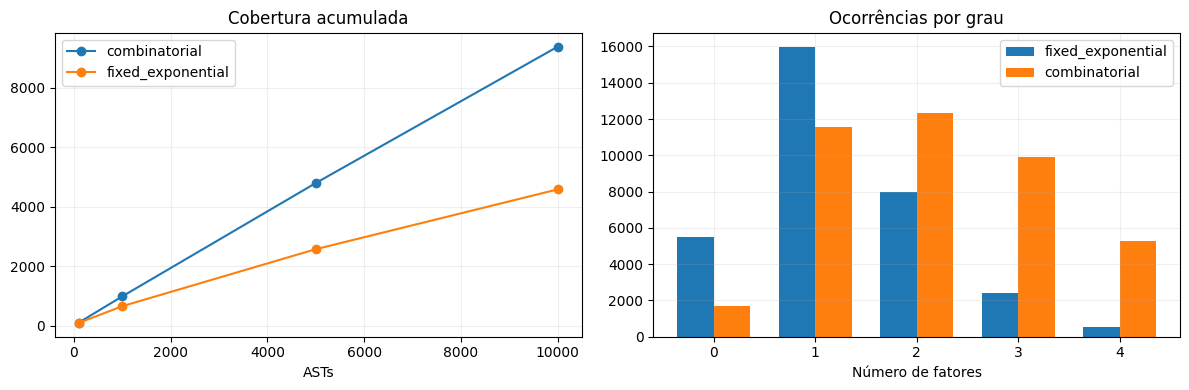

,Método,Posição,Skeleton,Ocorrências
0,fixed_exponential,1,1 + s_0[t-1],178
1,fixed_exponential,2,1 + s_0[t-3],171
2,fixed_exponential,3,1 + s_0[t-5],169
3,fixed_exponential,4,1 + s_0[t-4],169
4,fixed_exponential,5,1 + s_0[t-6],166
5,fixed_exponential,6,1 + s_0[t-2],164
6,fixed_exponential,7,1 + s_0[t-2] + s_0[t-6],94
7,fixed_exponential,8,1 + s_0[t-3] + s_0[t-4],92
8,fixed_exponential,9,1 + s_0[t-1] + s_0[t-6],91
9,fixed_exponential,10,1 + s_0[t-5] + s_0[t-6],87


In [3]:
prefix=pd.DataFrame([line for result in results.values() for line in result[4]],
                    columns=['Método','Árvores sorteadas','Skeletons diferentes'])
fig,axes=plt.subplots(1,2,figsize=(12,4))
for method,part in prefix.groupby('Método'):
    axes[0].plot(part['Árvores sorteadas'],part['Skeletons diferentes'],marker='o',label=method)
for method,r in results.items():
    axes[1].bar(np.arange(5)+(-.18 if method==METHODS[0] else .18),
                [r[2][d] for d in range(5)],width=.36,label=method)
axes[0].set(title='Cobertura acumulada',xlabel='ASTs')
axes[1].set(title='Ocorrências por grau',xlabel='Número de fatores')
for ax in axes:ax.legend();ax.grid(alpha=.2)
plt.tight_layout();plt.show()
top=[]
for method,r in results.items():
    for rank,(skeleton,count) in enumerate(r[0].most_common(10),1):
        top.append((method,rank,' + '.join(format_monomial(term) for term in skeleton) or '0',count))
display(pd.DataFrame(top,columns=['Método','Posição','Skeleton','Ocorrências']))


Os gráficos mostram a descoberta de skeletons e as ocorrências por grau. A amostragem combinatória muda simultaneamente as frequências de soma, produto e folhas, portanto a diferença observada não pode ser atribuída só ao número de operações.

## Registro do experimento

**Pergunta:** Como uma prior que favorece árvores com mais operações cobre skeletons comparada a uma amostragem uniforme de ASTs? **Configuração:** 10.000 ASTs por método; uma série; lags 1–6; 1–6 operações; grau 4; prior de operadores proporcional a exp(0,4(n-1)); probabilidades locais fixas de 0,4 parâmetro e 0,6 lag. Proteção escolhida com probabilidade 0,5 por amostra. **Seed:** 20261101, derivada por índice. **Proveniência:** `random_expression.py`, `combinatorial_expression.py`, `shao_wu.py`, `canonical_polynomial.py`. **Métricas:** aceitas, rejeitadas, skeletons distintos, concentração, diversidade efetiva, RAW/TANH, grau e proteção selecionada.  **Resultados (10.000 sorteios por método; p=0,5):** prior fixa: 4.580 skeletons, 56 rejeições, top 15 = 18,00%, diversidade efetiva 1.429,44; combinatória: 9.380 skeletons, 0 rejeições, top 15 = 1,48%, diversidade efetiva 8.852,89. **Resumo científico:** a prior combinatória espalhou mais amostras entre skeletons diferentes. **Reprodução:** `.venv/Scripts/python.exe -m jupyter nbconvert --to notebook --execute --inplace experiments/canonicalization/exponential_operator_prior/1_exponential_operator_coverage.ipynb`.